In [ ]:
pip install ucimlrepo

In [ ]:
from ucimlrepo import fetch_ucirepo
import pandas as pd


# fetch dataset
breast_cancer_wisconsin_diagnostic = fetch_ucirepo(id=17)

# data (as pandas dataframes)
X = breast_cancer_wisconsin_diagnostic.data.features
y = breast_cancer_wisconsin_diagnostic.data.targets

# metadata
#print(breast_cancer_wisconsin_diagnostic.metadata)

# variable information
#print(breast_cancer_wisconsin_diagnostic.variables)

print(X.head())
print(y.head())


   radius1  texture1  perimeter1   area1  smoothness1  compactness1  \
0    17.99     10.38      122.80  1001.0      0.11840       0.27760   
1    20.57     17.77      132.90  1326.0      0.08474       0.07864   
2    19.69     21.25      130.00  1203.0      0.10960       0.15990   
3    11.42     20.38       77.58   386.1      0.14250       0.28390   
4    20.29     14.34      135.10  1297.0      0.10030       0.13280   

   concavity1  concave_points1  symmetry1  fractal_dimension1  ...  radius3  \
0      0.3001          0.14710     0.2419             0.07871  ...    25.38   
1      0.0869          0.07017     0.1812             0.05667  ...    24.99   
2      0.1974          0.12790     0.2069             0.05999  ...    23.57   
3      0.2414          0.10520     0.2597             0.09744  ...    14.91   
4      0.1980          0.10430     0.1809             0.05883  ...    22.54   

   texture3  perimeter3   area3  smoothness3  compactness3  concavity3  \
0     17.33      184.60 

In [ ]:
# How big is our dataset? Any missing values?
print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")

# Summary of features
print(X.info())

# Count missing values
print(X.isnull().sum())

# Unique target classes
print("Target value counts:")
print(y.value_counts())


Features shape: (569, 30)
Target shape: (569, 1)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   radius1             569 non-null    float64
 1   texture1            569 non-null    float64
 2   perimeter1          569 non-null    float64
 3   area1               569 non-null    float64
 4   smoothness1         569 non-null    float64
 5   compactness1        569 non-null    float64
 6   concavity1          569 non-null    float64
 7   concave_points1     569 non-null    float64
 8   symmetry1           569 non-null    float64
 9   fractal_dimension1  569 non-null    float64
 10  radius2             569 non-null    float64
 11  texture2            569 non-null    float64
 12  perimeter2          569 non-null    float64
 13  area2               569 non-null    float64
 14  smoothness2         569 non-null    float64
 15  compactn

In [ ]:
# Quick summary stats on all features
pd.set_option('display.max_columns', 35)  # So you see all columns!
print(X.describe())

# Check target class distribution again
print(y['Diagnosis'].value_counts(normalize=True))


          radius1    texture1  perimeter1        area1  smoothness1  \
count  569.000000  569.000000  569.000000   569.000000   569.000000   
mean    14.127292   19.289649   91.969033   654.889104     0.096360   
std      3.524049    4.301036   24.298981   351.914129     0.014064   
min      6.981000    9.710000   43.790000   143.500000     0.052630   
25%     11.700000   16.170000   75.170000   420.300000     0.086370   
50%     13.370000   18.840000   86.240000   551.100000     0.095870   
75%     15.780000   21.800000  104.100000   782.700000     0.105300   
max     28.110000   39.280000  188.500000  2501.000000     0.163400   

       compactness1  concavity1  concave_points1   symmetry1  \
count    569.000000  569.000000       569.000000  569.000000   
mean       0.104341    0.088799         0.048919    0.181162   
std        0.052813    0.079720         0.038803    0.027414   
min        0.019380    0.000000         0.000000    0.106000   
25%        0.064920    0.029560         

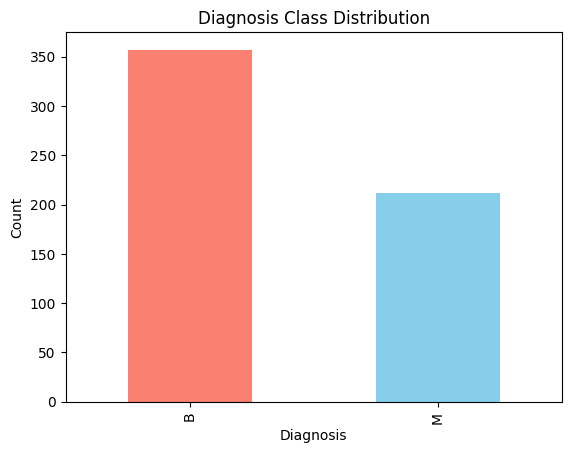

In [ ]:
import matplotlib.pyplot as plt

# Bar plot for diagnosis counts
y['Diagnosis'].value_counts().plot(kind='bar', color=['salmon', 'skyblue'])
plt.title("Diagnosis Class Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Count")
plt.show()


Feature-target correlations (descending):
concave_points3       0.793566
perimeter3            0.782914
concave_points1       0.776614
radius3               0.776454
perimeter1            0.742636
area3                 0.733825
radius1               0.730029
area1                 0.708984
concavity1            0.696360
concavity3            0.659610
compactness1          0.596534
compactness3          0.590998
radius2               0.567134
perimeter2            0.556141
area2                 0.548236
texture3              0.456903
smoothness3           0.421465
symmetry3             0.416294
texture1              0.415185
concave_points2       0.408042
smoothness1           0.358560
symmetry1             0.330499
fractal_dimension3    0.323872
compactness2          0.292999
concavity2            0.253730
fractal_dimension2    0.077972
symmetry2            -0.006522
texture2             -0.008303
fractal_dimension1   -0.012838
smoothness2          -0.067016
dtype: float64


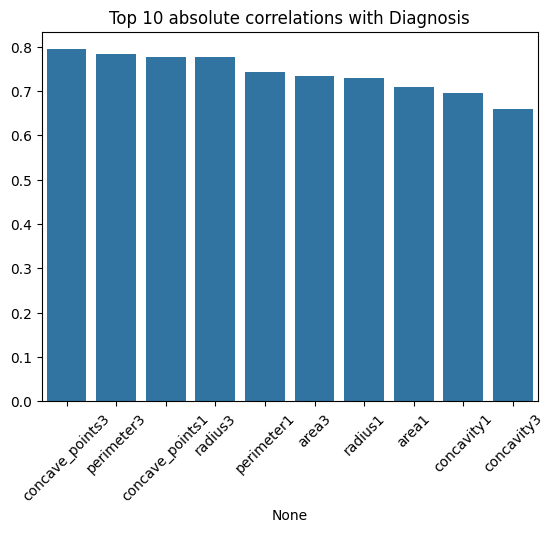

In [ ]:
# Check which features are most correlated with the target
import seaborn as sns

# Encode y for correlation (M=1, B=0)
y_num = y['Diagnosis'].map({'M':1, 'B':0})

# Simple feature-target correlation
correlations = X.corrwith(y_num).sort_values(ascending=False)
print("Feature-target correlations (descending):")
print(correlations)

# Visualize the strongest (top 10) correlations
top_corr = correlations.abs().sort_values(ascending=False)[:10]
sns.barplot(x=top_corr.index, y=top_corr.values)
plt.xticks(rotation=45)
plt.title('Top 10 absolute correlations with Diagnosis')
plt.show()


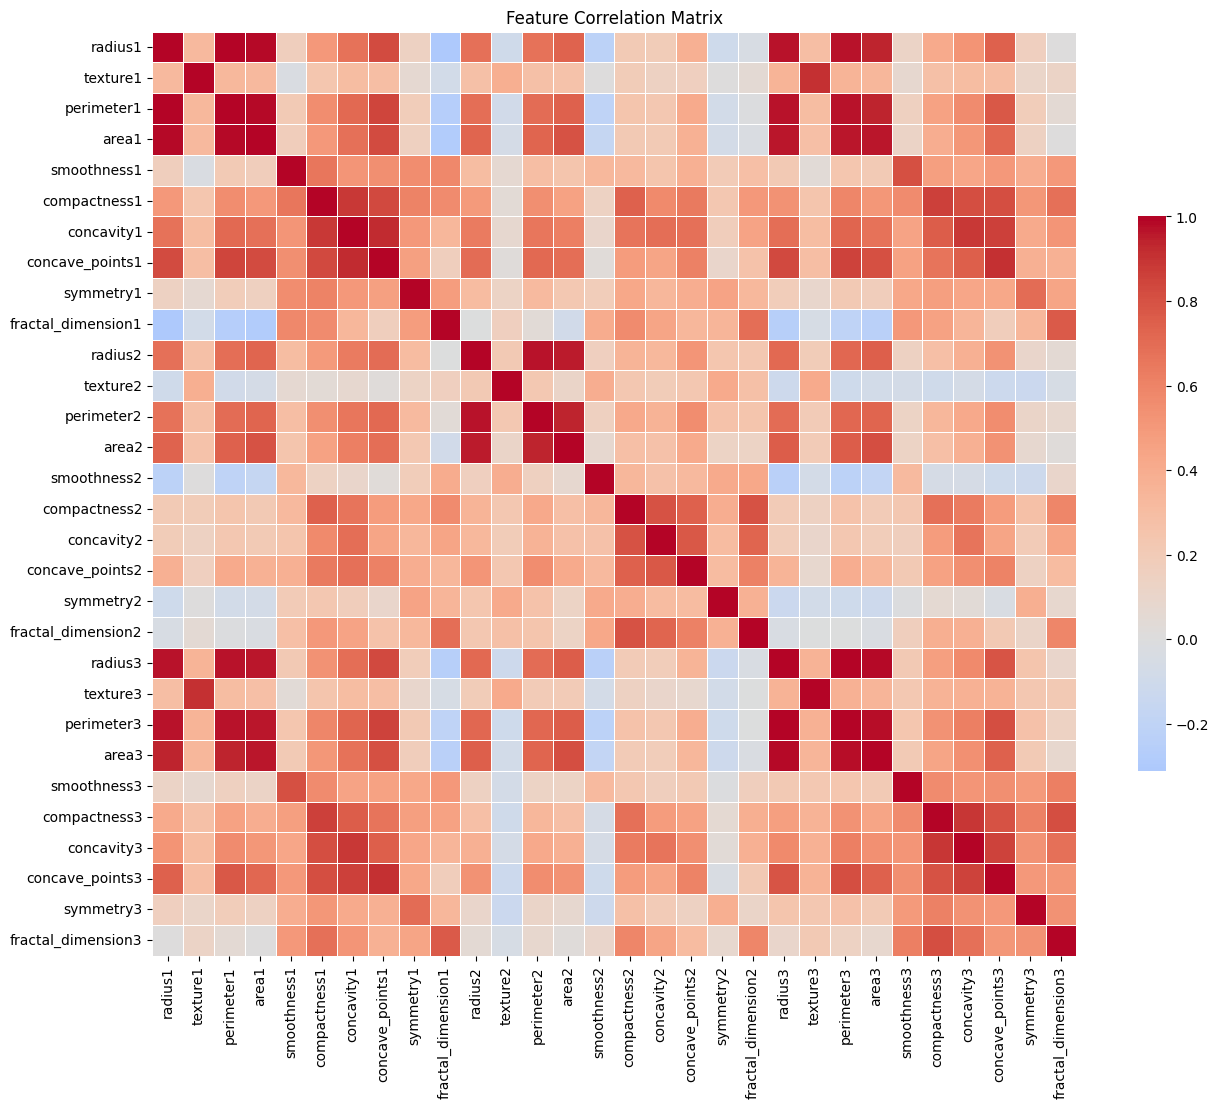

In [ ]:
plt.figure(figsize=(16, 12))
corr_matrix = X.corr()
sns.heatmap(corr_matrix, cmap='coolwarm', center=0,
            square=True, linewidths=.5, cbar_kws={'shrink': 0.6})
plt.title('Feature Correlation Matrix')
plt.show()


In [ ]:
y_num = y['Diagnosis'].map({'M': 1, 'B': 0})

In [ ]:
# ===== RLT IMPLEMENTATION: ROOT NODE =====

from sklearn.ensemble import ExtraTreesClassifier
import numpy as np

# Step 1: Compute Variable Importance at Root Node
# Using ExtraTreesClassifier as the embedded model (as per article)
print("=" * 60)
print("ROOT NODE - Computing Variable Importance")
print("=" * 60)

# Fit a quick embedded model to get variable importances
embedded_model = ExtraTreesClassifier(n_estimators=100, random_state=42, n_jobs=-1)
embedded_model.fit(X, y_num)

# Get feature importances
feature_importances = embedded_model.feature_importances_
feature_names = X.columns

# Create a dataframe for easier viewing
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': feature_importances
}).sort_values(by='Importance', ascending=False)

print("\nVariable Importance Ranking (Root Node):")
print(importance_df)

# Step 2: Apply Muting (50% as per article recommendation)
n_features = len(feature_names)
n_to_mute = int(0.5 * n_features)  # Mute 50%

print(f"\n{'='*60}")
print(f"Total features at root: {n_features}")
print(f"Muting rate: 50%")
print(f"Number to mute: {n_to_mute}")
print(f"{'='*60}")

# Get the features to mute (lowest importance)
muted_features = importance_df.tail(n_to_mute)['Feature'].tolist()
remaining_features = importance_df.head(n_features - n_to_mute)['Feature'].tolist()

print(f"\n✗ MUTED FEATURES (Bottom {n_to_mute}):")
for i, feat in enumerate(muted_features, 1):
    imp = importance_df[importance_df['Feature'] == feat]['Importance'].values[0]
    print(f"  {i}. {feat} (importance: {imp:.6f})")

print(f"\n✓ REMAINING FEATURES (Top {len(remaining_features)}):")
for i, feat in enumerate(remaining_features, 1):
    imp = importance_df[importance_df['Feature'] == feat]['Importance'].values[0]
    print(f"  {i}. {feat} (importance: {imp:.6f})")

# Step 3: Initialize Protected Set (empty at root, will add split variable)
protected_features = []

print(f"\n🛡️ PROTECTED SET: {protected_features if protected_features else 'Empty (will add split variable)'}")
print(f"\n{'='*60}")
print("ROOT NODE SUMMARY")
print(f"{'='*60}")
print(f"Muted: {len(muted_features)} features")
print(f"Remaining for split: {len(remaining_features)} features")
print(f"Protected: {len(protected_features)} features")


ROOT NODE - Computing Variable Importance

Variable Importance Ranking (Root Node):
               Feature  Importance
20             radius3    0.113826
22          perimeter3    0.090666
27     concave_points3    0.089214
23               area3    0.079068
7      concave_points1    0.072179
0              radius1    0.063327
6           concavity1    0.056557
3                area1    0.052100
26          concavity3    0.046758
13               area2    0.036877
2           perimeter1    0.034608
5         compactness1    0.028419
10             radius2    0.028176
25        compactness3    0.027098
21            texture3    0.022511
1             texture1    0.021275
24         smoothness3    0.021142
12          perimeter2    0.021001
28           symmetry3    0.012855
4          smoothness1    0.010493
17     concave_points2    0.010486
29  fractal_dimension3    0.009879
8            symmetry1    0.007654
15        compactness2    0.007541
9   fractal_dimension1    0.007179
19  fr

In [ ]:
# ===== ROOT NODE SPLIT =====

from sklearn.tree import DecisionTreeClassifier

print("\n" + "=" * 60)
print("ROOT NODE SPLIT")
print("=" * 60)

# Create subset with only remaining (non-muted) features
X_remaining = X[remaining_features]

# Fit a decision tree to find the best split variable
split_tree = DecisionTreeClassifier(max_depth=1, random_state=42)
split_tree.fit(X_remaining, y_num)

# Get the split feature (the feature used at the root of this shallow tree)
split_feature_idx = split_tree.tree_.feature[0]
split_feature_name = remaining_features[split_feature_idx]
split_threshold = split_tree.tree_.threshold[0]

print(f"\n✂️ SPLIT DECISION:")
print(f"   Feature: {split_feature_name}")
print(f"   Threshold: {split_threshold:.4f}")
print(f"   Rule: {split_feature_name} <= {split_threshold:.4f} → LEFT")
print(f"         {split_feature_name} >  {split_threshold:.4f} → RIGHT")

# Add split feature to protected set
protected_features.append(split_feature_name)
print(f"\n🛡️ PROTECTED SET (updated): {protected_features}")

# Split the data
left_mask = X[split_feature_name] <= split_threshold
right_mask = X[split_feature_name] > split_threshold

X_left = X[left_mask]
y_left = y_num[left_mask]

X_right = X[right_mask]
y_right = y_num[right_mask]

print(f"\n📊 DATA SPLIT:")
print(f"   Left child:  {len(X_left)} samples")
print(f"   Right child: {len(X_right)} samples")
print(f"   Total:       {len(X)} samples")

print("\n" + "=" * 60)
print("ROOT SPLIT COMPLETE - Ready for Child Nodes")
print("=" * 60)



ROOT NODE SPLIT

✂️ SPLIT DECISION:
   Feature: radius3
   Threshold: 16.7950
   Rule: radius3 <= 16.7950 → LEFT
         radius3 >  16.7950 → RIGHT

🛡️ PROTECTED SET (updated): ['radius3']

📊 DATA SPLIT:
   Left child:  379 samples
   Right child: 190 samples
   Total:       569 samples

ROOT SPLIT COMPLETE - Ready for Child Nodes


In [ ]:
# ===== LEFT CHILD NODE - Variable Importance & Muting =====

print("\n" + "=" * 60)
print("LEFT CHILD NODE - Computing Variable Importance")
print("=" * 60)
print(f"Samples in this node: {len(X_left)}")
print(f"Features available from parent: {len(remaining_features)}")
print(f"Protected features: {protected_features}")
print(f"Muted features so far: {len(muted_features)}")

# Create dataset with remaining features (exclude already muted)
X_left_remaining = X_left[remaining_features]

# Fit embedded model on LEFT CHILD data only
embedded_model_left = ExtraTreesClassifier(n_estimators=100, random_state=42, n_jobs=-1)
embedded_model_left.fit(X_left_remaining, y_left)

# Get feature importances for this node
feature_importances_left = embedded_model_left.feature_importances_

# Create importance dataframe
importance_df_left = pd.DataFrame({
    'Feature': remaining_features,
    'Importance': feature_importances_left
}).sort_values(by='Importance', ascending=False)

print("\nVariable Importance Ranking (Left Child Node):")
print(importance_df_left)

# Separate protected from unprotected features
unprotected_features = [f for f in remaining_features if f not in protected_features]
protected_in_remaining = [f for f in remaining_features if f in protected_features]

print(f"\n📋 Feature Status:")
print(f"   Protected (can't be muted): {len(protected_in_remaining)} → {protected_in_remaining}")
print(f"   Unprotected (eligible for muting): {len(unprotected_features)}")

# Mute 50% of UNPROTECTED features
n_unprotected = len(unprotected_features)
n_to_mute_left = int(0.5 * n_unprotected)

print(f"\n🔇 Muting Strategy:")
print(f"   Muting rate: 50% of unprotected")
print(f"   Number to mute at this node: {n_to_mute_left}")

# Get importances for unprotected features only
importance_unprotected = importance_df_left[importance_df_left['Feature'].isin(unprotected_features)]

# Mute the lowest importance unprotected features
newly_muted = importance_unprotected.tail(n_to_mute_left)['Feature'].tolist()
muted_features_left = muted_features + newly_muted  # Cumulative muted set

# Remaining features for next split
remaining_features_left = [f for f in remaining_features if f not in newly_muted]

print(f"\n✗ NEWLY MUTED at Left Child (Bottom {n_to_mute_left}):")
for i, feat in enumerate(newly_muted, 1):
    imp = importance_df_left[importance_df_left['Feature'] == feat]['Importance'].values[0]
    print(f"  {i}. {feat} (importance: {imp:.6f})")

print(f"\n✓ REMAINING FEATURES for next split: {len(remaining_features_left)}")
for i, feat in enumerate(remaining_features_left, 1):
    imp = importance_df_left[importance_df_left['Feature'] == feat]['Importance'].values[0]
    protected_marker = "🛡️" if feat in protected_features else ""
    print(f"  {i}. {feat} (importance: {imp:.6f}) {protected_marker}")

print(f"\n{'='*60}")
print("LEFT CHILD NODE SUMMARY")
print(f"{'='*60}")
print(f"Total muted (cumulative): {len(muted_features_left)} features")
print(f"Remaining for next split: {len(remaining_features_left)} features")
print(f"Protected: {len(protected_features)} features → {protected_features}")



LEFT CHILD NODE - Computing Variable Importance
Samples in this node: 379
Features available from parent: 15
Protected features: ['radius3']
Muted features so far: 15

Variable Importance Ranking (Left Child Node):
            Feature  Importance
2   concave_points3    0.177288
4   concave_points1    0.113357
6        concavity1    0.087051
13     compactness3    0.070555
14         texture3    0.067010
8        concavity3    0.064277
3             area3    0.058720
1        perimeter3    0.058088
11     compactness1    0.055912
0           radius3    0.052984
10       perimeter1    0.047221
5           radius1    0.039678
12          radius2    0.038936
9             area2    0.036568
7             area1    0.032356

📋 Feature Status:
   Protected (can't be muted): 1 → ['radius3']
   Unprotected (eligible for muting): 14

🔇 Muting Strategy:
   Muting rate: 50% of unprotected
   Number to mute at this node: 7

✗ NEWLY MUTED at Left Child (Bottom 7):
  1. perimeter3 (importance: 0.0580

In [ ]:
# ===== COMPLETE RLT TREE WITH STOPPING CRITERIA =====

class RLTNode:
    """Represents a node in the RLT tree"""
    def __init__(self, depth=0, samples=None, feature_name=None, threshold=None):
        self.depth = depth
        self.samples = samples
        self.feature_name = feature_name  # Split feature
        self.threshold = threshold
        self.left = None
        self.right = None
        self.is_leaf = False
        self.prediction = None  # For leaf nodes
        self.muted_features = []
        self.protected_features = []
        self.remaining_features = []

def should_stop_split(X_node, y_node, remaining_features, depth, min_node_size=20, max_depth=15):
    """
    Check if we should stop splitting based on article's criteria

    Parameters:
    - min_node_size: Minimum samples required to split (article uses 20)
    - max_depth: Maximum tree depth (article uses 15-20)
    """

    # Criterion 1: Not enough samples
    if len(X_node) < min_node_size:
        return True, f"Node size ({len(X_node)}) < min_node_size ({min_node_size})"

    # Criterion 2: Maximum depth reached
    if depth >= max_depth:
        return True, f"Max depth ({max_depth}) reached"

    # Criterion 3: Pure node (all same class)
    if len(np.unique(y_node)) == 1:
        return True, "Pure node (all samples same class)"

    # Criterion 4: No features left to split
    if len(remaining_features) <= 1:
        return True, f"Insufficient features to split ({len(remaining_features)} remaining)"

    return False, None

# Test the stopping function
print("=" * 60)
print("TESTING STOPPING CRITERIA")
print("=" * 60)

# Test on left child node
stop, reason = should_stop_split(X_left, y_left, remaining_features_left, depth=1)
print(f"\nLeft Child Node (depth=1, samples={len(X_left)}, features={len(remaining_features_left)}):")
print(f"  Should stop? {stop}")
if reason:
    print(f"  Reason: {reason}")
else:
    print(f"  ✓ Continue splitting")

# Test with different scenarios
print("\n" + "=" * 60)
print("TESTING DIFFERENT SCENARIOS")
print("=" * 60)

# Scenario 1: Too few samples
small_X = X_left.iloc[:10]
small_y = y_left.iloc[:10]
stop, reason = should_stop_split(small_X, small_y, remaining_features_left, depth=1, min_node_size=20)
print(f"\n1. Small node (10 samples):")
print(f"   Should stop? {stop}")
print(f"   Reason: {reason}")

# Scenario 2: Max depth
stop, reason = should_stop_split(X_left, y_left, remaining_features_left, depth=15, max_depth=15)
print(f"\n2. At max depth (15):")
print(f"   Should stop? {stop}")
print(f"   Reason: {reason}")

# Scenario 3: Only 1 feature left
stop, reason = should_stop_split(X_left, y_left, ['radius3'], depth=1)
print(f"\n3. Only 1 feature remaining:")
print(f"   Should stop? {stop}")
print(f"   Reason: {reason}")

print("\n" + "=" * 60)
print("Article's Default Settings:")
print("  - min_node_size: 20 samples")
print("  - max_depth: 15-20 levels")
print("  - muting_rate: 50% per node")
print("=" * 60)


TESTING STOPPING CRITERIA

Left Child Node (depth=1, samples=379, features=8):
  Should stop? False
  ✓ Continue splitting

TESTING DIFFERENT SCENARIOS

1. Small node (10 samples):
   Should stop? True
   Reason: Node size (10) < min_node_size (20)

2. At max depth (15):
   Should stop? True
   Reason: Max depth (15) reached

3. Only 1 feature remaining:
   Should stop? True
   Reason: Insufficient features to split (1 remaining)

Article's Default Settings:
  - min_node_size: 20 samples
  - max_depth: 15-20 levels
  - muting_rate: 50% per node


In [ ]:
# ===== COMPLETE AUTOMATED RLT TREE IMPLEMENTATION =====

import numpy as np
import pandas as pd
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.tree import DecisionTreeClassifier

class RLTNode:
    """Node in the RLT tree"""
    def __init__(self):
        self.feature_name = None
        self.threshold = None
        self.left = None
        self.right = None
        self.is_leaf = False
        self.prediction = None
        self.depth = 0
        self.n_samples = 0

class RLTClassifier:
    """
    Reinforcement Learning Tree (RLT) Classifier
    Implements the algorithm from Zhu et al. (2015)
    """

    def __init__(self,
                 muting_rate=0.5,
                 p0=0,
                 min_node_size=20,
                 max_depth=15,
                 random_state=42):
        """
        Parameters:
        -----------
        muting_rate : float (default=0.5)
            Percentage of features to mute at each node (article recommends 0.5)
        p0 : int (default=0)
            Number of protected features at root (article says 0 is fine)
        min_node_size : int (default=20)
            Minimum samples required to split a node (article uses 20)
        max_depth : int (default=15)
            Maximum tree depth (article uses 15-20)
        random_state : int
            Random seed for reproducibility
        """
        self.muting_rate = muting_rate
        self.p0 = p0
        self.min_node_size = min_node_size
        self.max_depth = max_depth
        self.random_state = random_state
        self.root = None
        self.feature_names = None
        self.classes_ = None

    def fit(self, X, y):
        """
        Build the RLT tree from training data

        Parameters:
        -----------
        X : DataFrame or array, shape (n_samples, n_features)
            Training features
        y : array, shape (n_samples,)
            Target values
        """
        # Convert to DataFrame if needed
        if not isinstance(X, pd.DataFrame):
            X = pd.DataFrame(X, columns=[f"feature_{i}" for i in range(X.shape[1])])

        if isinstance(y, pd.Series):
            y = y.values

        self.feature_names = list(X.columns)
        self.classes_ = np.unique(y)

        # Initialize: no muted features, no protected features at root
        initial_muted = []
        initial_protected = []

        print("=" * 60)
        print("BUILDING RLT TREE")
        print("=" * 60)
        print(f"Total samples: {len(X)}")
        print(f"Total features: {len(self.feature_names)}")
        print(f"Muting rate: {self.muting_rate * 100}%")
        print(f"Min node size: {self.min_node_size}")
        print(f"Max depth: {self.max_depth}")
        print("=" * 60)

        # Build tree recursively
        self.root = self._build_tree(X, y,
                                      muted_features=initial_muted,
                                      protected_features=initial_protected,
                                      depth=0)

        print("\n✓ Tree building complete!")
        return self

    def _build_tree(self, X, y, muted_features, protected_features, depth):
        """
        Recursively build the tree
        """
        node = RLTNode()
        node.depth = depth
        node.n_samples = len(X)

        # Get remaining features (not muted)
        remaining_features = [f for f in self.feature_names if f not in muted_features]

        # Check stopping criteria
        should_stop, reason = self._should_stop(X, y, remaining_features, depth)

        if should_stop:
            # Create leaf node
            node.is_leaf = True
            node.prediction = np.bincount(y.astype(int)).argmax()
            print(f"{'  ' * depth}└─ Leaf at depth {depth}: {node.n_samples} samples → class {node.prediction} ({reason})")
            return node

        # Compute variable importance on remaining features
        X_remaining = X[remaining_features]

        embedded_model = ExtraTreesClassifier(n_estimators=100,
                                              random_state=self.random_state,
                                              n_jobs=-1)
        embedded_model.fit(X_remaining, y)

        # Get importance ranking
        importances = embedded_model.feature_importances_
        importance_df = pd.DataFrame({
            'feature': remaining_features,
            'importance': importances
        }).sort_values('importance', ascending=False)

        # Separate protected from unprotected
        unprotected = [f for f in remaining_features if f not in protected_features]

        # Mute lowest importance unprotected features
        n_to_mute = int(self.muting_rate * len(unprotected))

        if n_to_mute > 0:
            importance_unprotected = importance_df[importance_df['feature'].isin(unprotected)]
            newly_muted = importance_unprotected.tail(n_to_mute)['feature'].tolist()
            updated_muted = muted_features + newly_muted
        else:
            updated_muted = muted_features

        # Find best split among remaining features
        remaining_after_mute = [f for f in remaining_features if f not in updated_muted]

        if len(remaining_after_mute) == 0:
            # No features left, create leaf
            node.is_leaf = True
            node.prediction = np.bincount(y.astype(int)).argmax()
            print(f"{'  ' * depth}└─ Leaf at depth {depth}: {node.n_samples} samples → class {node.prediction} (no features left)")
            return node

        X_for_split = X[remaining_after_mute]
        split_tree = DecisionTreeClassifier(max_depth=1, random_state=self.random_state)
        split_tree.fit(X_for_split, y)

        split_idx = split_tree.tree_.feature[0]
        split_feature = remaining_after_mute[split_idx]
        split_threshold = split_tree.tree_.threshold[0]

        # Update protected set with split feature
        updated_protected = protected_features + [split_feature]

        print(f"{'  ' * depth}├─ Split at depth {depth}: {split_feature} <= {split_threshold:.4f} ({node.n_samples} samples)")

        # Split data
        left_mask = X[split_feature] <= split_threshold
        right_mask = X[split_feature] > split_threshold

        X_left, y_left = X[left_mask], y[left_mask]
        X_right, y_right = X[right_mask], y[right_mask]

        # Store split info
        node.feature_name = split_feature
        node.threshold = split_threshold

        # Recursively build children
        node.left = self._build_tree(X_left, y_left, updated_muted, updated_protected, depth + 1)
        node.right = self._build_tree(X_right, y_right, updated_muted, updated_protected, depth + 1)

        return node

    def _should_stop(self, X, y, remaining_features, depth):
        """Check if we should stop splitting"""

        if len(X) < self.min_node_size:
            return True, f"n_samples={len(X)} < min_node_size={self.min_node_size}"

        if depth >= self.max_depth:
            return True, f"depth={depth} >= max_depth={self.max_depth}"

        if len(np.unique(y)) == 1:
            return True, "pure node"

        if len(remaining_features) <= 1:
            return True, f"only {len(remaining_features)} feature(s) left"

        return False, None

    def predict(self, X):
        """Predict class labels for samples in X"""
        if not isinstance(X, pd.DataFrame):
            X = pd.DataFrame(X, columns=self.feature_names)

        predictions = []
        for idx in range(len(X)):
            predictions.append(self._predict_sample(X.iloc[idx], self.root))

        return np.array(predictions)

    def _predict_sample(self, sample, node):
        """Predict a single sample by traversing the tree"""
        if node.is_leaf:
            return node.prediction

        if sample[node.feature_name] <= node.threshold:
            return self._predict_sample(sample, node.left)
        else:
            return self._predict_sample(sample, node.right)

print("✓ RLTClassifier class defined successfully!")
print("Ready to train on any dataset with: rlt = RLTClassifier().fit(X, y)")


✓ RLTClassifier class defined successfully!
Ready to train on any dataset with: rlt = RLTClassifier().fit(X, y)


In [ ]:
# ===== TRAIN RLT ON BREAST CANCER DATASET =====

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("\n" + "=" * 60)
print("TRAINING RLT ON BREAST CANCER WISCONSIN DATASET")
print("=" * 60)

# Split data into train/test
X_train, X_test, y_train, y_test = train_test_split(
    X, y_num,
    test_size=0.2,
    random_state=42,
    stratify=y_num
)

print(f"\nTrain set: {len(X_train)} samples")
print(f"Test set: {len(X_test)} samples")
print(f"Class distribution in train: {np.bincount(y_train)}")
print(f"Class distribution in test: {np.bincount(y_test)}")

# Create and train RLT model with article's settings
rlt_model = RLTClassifier(
    muting_rate=0.5,      # 50% muting (article's recommendation)
    p0=0,                  # No initial protected features
    min_node_size=20,      # Article's default
    max_depth=15,          # Article's default
    random_state=42
)

# Fit the model (this will print the tree structure as it builds)
print("\n" + "=" * 60)
print("BUILDING TREE...")
print("=" * 60)
rlt_model.fit(X_train, y_train)

# Make predictions on test set
print("\n" + "=" * 60)
print("MAKING PREDICTIONS ON TEST SET")
print("=" * 60)
y_pred = rlt_model.predict(X_test)

# Evaluate performance
accuracy = accuracy_score(y_test, y_pred)
print(f"\n✓ Test Accuracy: {accuracy:.4f} ({accuracy*100:.2f}%)")

print("\n" + "=" * 60)
print("CLASSIFICATION REPORT")
print("=" * 60)
print(classification_report(y_test, y_pred, target_names=['Benign', 'Malignant']))

print("=" * 60)
print("CONFUSION MATRIX")
print("=" * 60)
cm = confusion_matrix(y_test, y_pred)
print(cm)
print(f"\nTrue Negatives (Benign correctly classified): {cm[0,0]}")
print(f"False Positives (Benign misclassified as Malignant): {cm[0,1]}")
print(f"False Negatives (Malignant misclassified as Benign): {cm[1,0]}")
print(f"True Positives (Malignant correctly classified): {cm[1,1]}")



TRAINING RLT ON BREAST CANCER WISCONSIN DATASET

Train set: 455 samples
Test set: 114 samples
Class distribution in train: [285 170]
Class distribution in test: [72 42]

BUILDING TREE...
BUILDING RLT TREE
Total samples: 455
Total features: 30
Muting rate: 50.0%
Min node size: 20
Max depth: 15
├─ Split at depth 0: perimeter3 <= 112.8000 (455 samples)
  ├─ Split at depth 1: concave_points3 <= 0.1603 (297 samples)
    ├─ Split at depth 2: concave_points3 <= 0.1359 (285 samples)
      ├─ Split at depth 3: area3 <= 929.8000 (265 samples)
        ├─ Split at depth 4: area3 <= 874.8500 (264 samples)
          ├─ Split at depth 5: area3 <= 650.9500 (261 samples)
            ├─ Split at depth 6: concave_points1 <= 0.0350 (203 samples)
              └─ Leaf at depth 7: 181 samples → class 0 (pure node)
              ├─ Split at depth 7: concave_points1 <= 0.0361 (22 samples)
                └─ Leaf at depth 8: 1 samples → class 1 (n_samples=1 < min_node_size=20)
                └─ Leaf at depth

VISUALIZATION 1: Confusion Matrix Heatmap


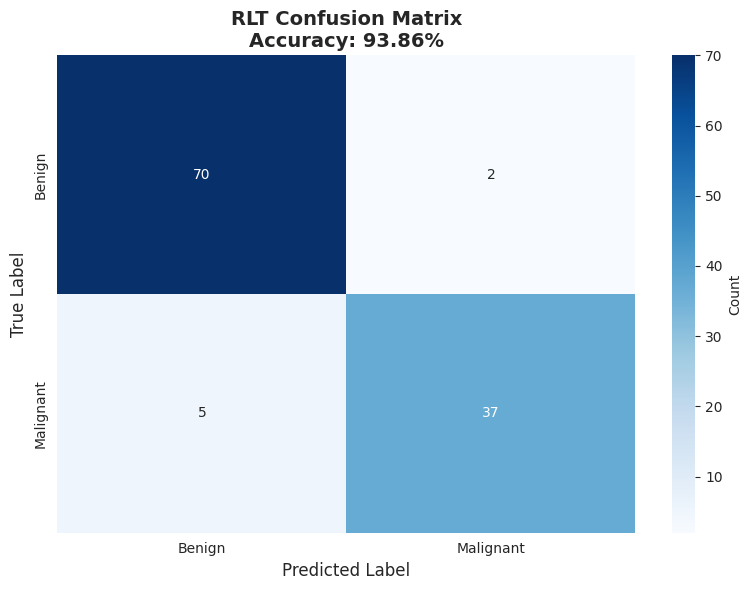


VISUALIZATION 2: Performance Metrics by Class


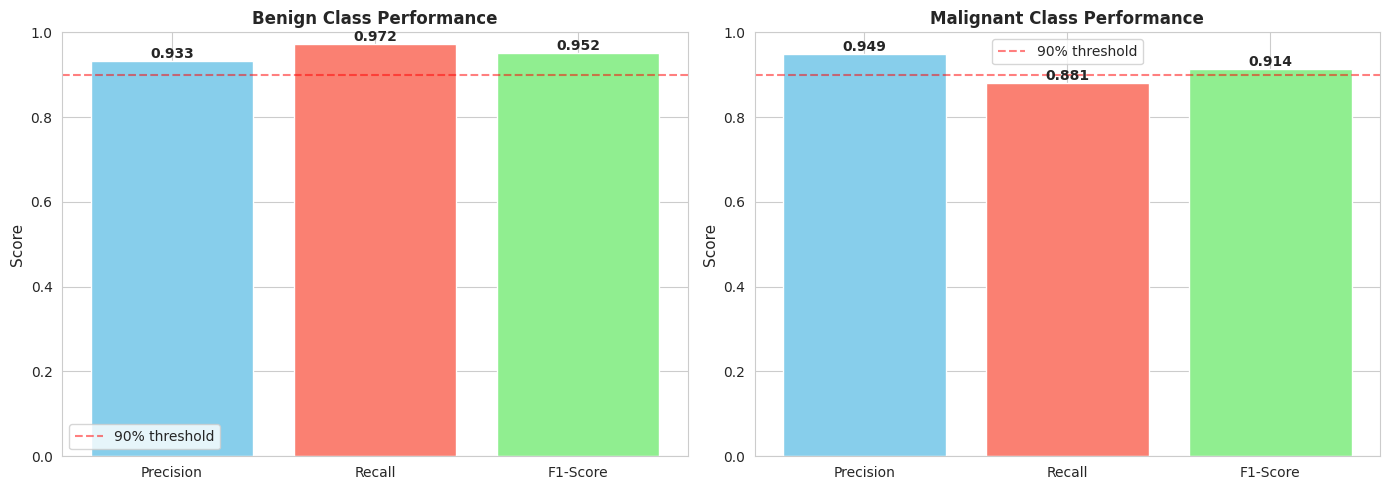


VISUALIZATION 3: Class Distribution Comparison


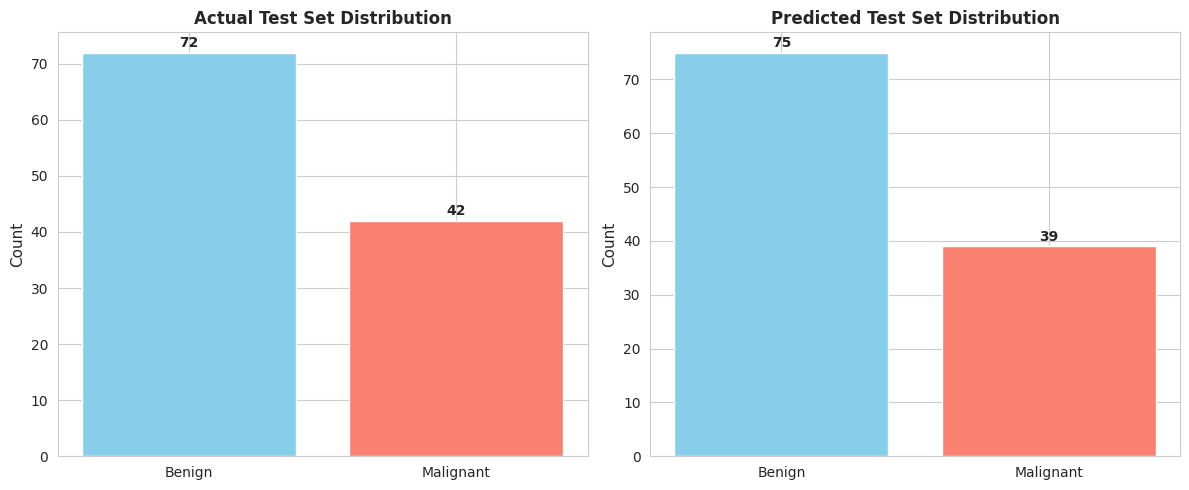


✓ Visualizations complete!


In [ ]:
# ===== VISUALIZATIONS FOR RLT MODEL =====

import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 8)

# 1. CONFUSION MATRIX HEATMAP
print("=" * 60)
print("VISUALIZATION 1: Confusion Matrix Heatmap")
print("=" * 60)

fig, ax = plt.subplots(1, 1, figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Benign', 'Malignant'],
            yticklabels=['Benign', 'Malignant'],
            cbar_kws={'label': 'Count'})
plt.title('RLT Confusion Matrix\nAccuracy: 93.86%', fontsize=14, fontweight='bold')
plt.ylabel('True Label', fontsize=12)
plt.xlabel('Predicted Label', fontsize=12)
plt.tight_layout()
plt.show()

# 2. PERFORMANCE METRICS BAR CHART
print("\n" + "=" * 60)
print("VISUALIZATION 2: Performance Metrics by Class")
print("=" * 60)

from sklearn.metrics import precision_score, recall_score, f1_score

metrics_data = {
    'Benign': {
        'Precision': precision_score(y_test, y_pred, pos_label=0),
        'Recall': recall_score(y_test, y_pred, pos_label=0),
        'F1-Score': f1_score(y_test, y_pred, pos_label=0)
    },
    'Malignant': {
        'Precision': precision_score(y_test, y_pred, pos_label=1),
        'Recall': recall_score(y_test, y_pred, pos_label=1),
        'F1-Score': f1_score(y_test, y_pred, pos_label=1)
    }
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for idx, (class_name, metrics) in enumerate(metrics_data.items()):
    ax = axes[idx]
    metric_names = list(metrics.keys())
    metric_values = list(metrics.values())

    bars = ax.bar(metric_names, metric_values, color=['skyblue', 'salmon', 'lightgreen'])
    ax.set_ylim(0, 1.0)
    ax.set_ylabel('Score', fontsize=11)
    ax.set_title(f'{class_name} Class Performance', fontsize=12, fontweight='bold')
    ax.axhline(y=0.9, color='red', linestyle='--', alpha=0.5, label='90% threshold')

    # Add value labels on bars
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.3f}',
                ha='center', va='bottom', fontsize=10, fontweight='bold')

    ax.legend()

plt.tight_layout()
plt.show()

# 3. CLASS DISTRIBUTION (ACTUAL VS PREDICTED)
print("\n" + "=" * 60)
print("VISUALIZATION 3: Class Distribution Comparison")
print("=" * 60)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Actual distribution
axes[0].bar(['Benign', 'Malignant'], np.bincount(y_test), color=['skyblue', 'salmon'])
axes[0].set_title('Actual Test Set Distribution', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Count', fontsize=11)
for i, v in enumerate(np.bincount(y_test)):
    axes[0].text(i, v + 1, str(v), ha='center', fontweight='bold')

# Predicted distribution
axes[1].bar(['Benign', 'Malignant'], np.bincount(y_pred), color=['skyblue', 'salmon'])
axes[1].set_title('Predicted Test Set Distribution', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Count', fontsize=11)
for i, v in enumerate(np.bincount(y_pred)):
    axes[1].text(i, v + 1, str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

print("\n✓ Visualizations complete!")


In [ ]:
# ===== INTERACTIVE PREDICTION FUNCTION =====

def predict_cancer(model, features_dict):
    """
    Make a prediction using the trained RLT model

    Parameters:
    -----------
    model : trained RLTClassifier
        Your trained RLT model
    features_dict : dict
        Dictionary with feature names and values (all 30 features)

    Returns:
    --------
    prediction : str
        "Benign" or "Malignant"
    """
    # Convert dictionary to DataFrame (model expects DataFrame)
    input_df = pd.DataFrame([features_dict])

    # Make prediction (0 = Benign, 1 = Malignant)
    prediction = model.predict(input_df)[0]

    # Convert to readable format
    result = "Benign (No Cancer)" if prediction == 0 else "Malignant (Cancer)"

    return prediction, result

# ===== EXAMPLE 1: Test with a sample from the test set =====
print("=" * 60)
print("EXAMPLE 1: Testing with an actual patient from test set")
print("=" * 60)

# Get one benign patient from test set
benign_sample_idx = y_test[y_test == 0].index[0]
benign_features = X_test.loc[benign_sample_idx].to_dict()

print("\n📋 Patient Features (first 5 for brevity):")
for i, (key, value) in enumerate(list(benign_features.items())[:5]):
    print(f"   {key}: {value:.4f}")
print("   ...")

pred_num, pred_text = predict_cancer(rlt_model, benign_features)
actual = "Benign" if y_test[benign_sample_idx] == 0 else "Malignant"

print(f"\n🔍 PREDICTION: {pred_text}")
print(f"✅ ACTUAL: {actual}")
print(f"{'✓ CORRECT!' if pred_text.startswith(actual) else '✗ INCORRECT!'}")

# ===== EXAMPLE 2: Test with a malignant patient =====
print("\n" + "=" * 60)
print("EXAMPLE 2: Testing with a malignant patient from test set")
print("=" * 60)

# Get one malignant patient from test set
malignant_sample_idx = y_test[y_test == 1].index[0]
malignant_features = X_test.loc[malignant_sample_idx].to_dict()

print("\n📋 Patient Features (first 5 for brevity):")
for i, (key, value) in enumerate(list(malignant_features.items())[:5]):
    print(f"   {key}: {value:.4f}")
print("   ...")

pred_num, pred_text = predict_cancer(rlt_model, malignant_features)
actual = "Benign" if y_test[malignant_sample_idx] == 0 else "Malignant"

print(f"\n🔍 PREDICTION: {pred_text}")
print(f"✅ ACTUAL: {actual}")
print(f"{'✓ CORRECT!' if pred_text.startswith(actual) else '✗ INCORRECT!'}")

# ===== EXAMPLE 3: Manual input (you can change these values!) =====
print("\n" + "=" * 60)
print("EXAMPLE 3: Manual prediction with custom values")
print("=" * 60)

# Create a custom patient (using average values from benign cases)
custom_patient = {
    'radius1': 12.0,
    'texture1': 18.0,
    'perimeter1': 80.0,
    'area1': 450.0,
    'smoothness1': 0.10,
    'compactness1': 0.08,
    'concavity1': 0.05,
    'concave_points1': 0.03,
    'symmetry1': 0.18,
    'fractal_dimension1': 0.06,
    'radius2': 0.4,
    'texture2': 1.2,
    'perimeter2': 3.0,
    'area2': 40.0,
    'smoothness2': 0.007,
    'compactness2': 0.02,
    'concavity2': 0.03,
    'concave_points2': 0.01,
    'symmetry2': 0.02,
    'fractal_dimension2': 0.003,
    'radius3': 13.5,
    'texture3': 24.0,
    'perimeter3': 90.0,
    'area3': 550.0,
    'smoothness3': 0.13,
    'compactness3': 0.15,
    'concavity3': 0.12,
    'concave_points3': 0.07,
    'symmetry3': 0.25,
    'fractal_dimension3': 0.08
}

print("\n📋 Custom Patient Features (showing all 30):")
for key, value in custom_patient.items():
    print(f"   {key}: {value}")

pred_num, pred_text = predict_cancer(rlt_model, custom_patient)

print(f"\n🔍 PREDICTION: {pred_text}")
print(f"\n💡 TIP: You can change the values in 'custom_patient' dictionary above to test different scenarios!")

print("\n" + "=" * 60)
print("✓ Prediction function ready!")
print("=" * 60)


EXAMPLE 1: Testing with an actual patient from test set

📋 Patient Features (first 5 for brevity):
   radius1: 11.4100
   texture1: 10.8200
   perimeter1: 73.3400
   area1: 403.3000
   smoothness1: 0.0937
   ...

🔍 PREDICTION: Benign (No Cancer)
✅ ACTUAL: Benign
✓ CORRECT!

EXAMPLE 2: Testing with a malignant patient from test set

📋 Patient Features (first 5 for brevity):
   radius1: 20.9400
   texture1: 23.5600
   perimeter1: 138.9000
   area1: 1364.0000
   smoothness1: 0.1007
   ...

🔍 PREDICTION: Malignant (Cancer)
✅ ACTUAL: Malignant
✓ CORRECT!

EXAMPLE 3: Manual prediction with custom values

📋 Custom Patient Features (showing all 30):
   radius1: 12.0
   texture1: 18.0
   perimeter1: 80.0
   area1: 450.0
   smoothness1: 0.1
   compactness1: 0.08
   concavity1: 0.05
   concave_points1: 0.03
   symmetry1: 0.18
   fractal_dimension1: 0.06
   radius2: 0.4
   texture2: 1.2
   perimeter2: 3.0
   area2: 40.0
   smoothness2: 0.007
   compactness2: 0.02
   concavity2: 0.03
   concave_poi

In [ ]:
# ===== INSTALL GRADIO =====
!pip install gradio -q

import gradio as gr

# ===== CREATE INTERACTIVE WEB INTERFACE =====

def predict_with_gradio(*feature_values):
    """
    Gradio interface function
    Takes 30 individual feature values and returns prediction
    """
    # Create feature dictionary
    feature_names = list(X.columns)
    features_dict = {name: value for name, value in zip(feature_names, feature_values)}

    # Make prediction
    pred_num, pred_text = predict_cancer(rlt_model, features_dict)

    # Return result with styling
    if pred_num == 0:
        result = f"✅ **PREDICTION: {pred_text}**"
        color = "green"
    else:
        result = f"⚠️ **PREDICTION: {pred_text}**"
        color = "red"

    return result

# Create interface with all 30 features
print("=" * 60)
print("CREATING INTERACTIVE WEB INTERFACE...")
print("=" * 60)

# Get feature names
feature_names = list(X.columns)

# Create input components (sliders for each feature)
# Using reasonable ranges based on the dataset
inputs = []
for feature in feature_names:
    min_val = float(X[feature].min())
    max_val = float(X[feature].max())
    mean_val = float(X[feature].mean())

    inputs.append(
        gr.Slider(
            minimum=min_val,
            maximum=max_val,
            value=mean_val,
            label=feature,
            step=(max_val - min_val) / 100
        )
    )

# Create Gradio interface
interface = gr.Interface(
    fn=predict_with_gradio,
    inputs=inputs,
    outputs=gr.Markdown(label="Prediction Result"),
    title="🏥 Breast Cancer Prediction with RLT",
    description="""
    ### Interactive Breast Cancer Diagnosis Predictor

    Adjust the sliders below to input patient measurements.
    The model will predict whether the tumor is **Benign** or **Malignant**.

    **All 30 features are available** (scroll down to see all sliders).

    📊 Model: Reinforcement Learning Tree (RLT)
    🎯 Accuracy: 93.86%
    """,
    theme="default",
    allow_flagging="never"
)

# Launch the interface
print("\n🚀 Launching web interface...")
print("=" * 60)
interface.launch(share=True, debug=False)


CREATING INTERACTIVE WEB INTERFACE...


/usr/local/lib/python3.12/dist-packages/gradio/interface.py:415: UserWarning: The `allow_flagging` parameter in `Interface` is deprecated. Use `flagging_mode` instead.
  warnings.warn(



🚀 Launching web interface...
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f381cb2e75491a16db.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# ===== MODEL COMPARISON: RLT vs OTHER CLASSIFIERS =====

from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import time

print("=" * 60)
print("BENCHMARK: COMPARING RLT WITH OTHER MODELS")
print("=" * 60)

# Dictionary to store results
results = {}

# 1. RLT (already trained)
print("\n1️⃣ RLT (Already trained)")
rlt_pred = rlt_model.predict(X_test)
results['RLT'] = {
    'Accuracy': accuracy_score(y_test, rlt_pred),
    'Precision': precision_score(y_test, rlt_pred),
    'Recall': recall_score(y_test, rlt_pred),
    'F1-Score': f1_score(y_test, rlt_pred)
}
print(f"   ✓ Accuracy: {results['RLT']['Accuracy']:.4f}")

# 2. Random Forest
print("\n2️⃣ Random Forest")
start = time.time()
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)
rf_time = time.time() - start
results['Random Forest'] = {
    'Accuracy': accuracy_score(y_test, rf_pred),
    'Precision': precision_score(y_test, rf_pred),
    'Recall': recall_score(y_test, rf_pred),
    'F1-Score': f1_score(y_test, rf_pred),
    'Time': rf_time
}
print(f"   ✓ Accuracy: {results['Random Forest']['Accuracy']:.4f} (trained in {rf_time:.2f}s)")

# 3. Decision Tree
print("\n3️⃣ Decision Tree")
start = time.time()
dt_model = DecisionTreeClassifier(max_depth=15, random_state=42)
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)
dt_time = time.time() - start
results['Decision Tree'] = {
    'Accuracy': accuracy_score(y_test, dt_pred),
    'Precision': precision_score(y_test, dt_pred),
    'Recall': recall_score(y_test, dt_pred),
    'F1-Score': f1_score(y_test, dt_pred),
    'Time': dt_time
}
print(f"   ✓ Accuracy: {results['Decision Tree']['Accuracy']:.4f} (trained in {dt_time:.2f}s)")

# 4. Gradient Boosting
print("\n4️⃣ Gradient Boosting")
start = time.time()
gb_model = GradientBoostingClassifier(n_estimators=100, random_state=42)
gb_model.fit(X_train, y_train)
gb_pred = gb_model.predict(X_test)
gb_time = time.time() - start
results['Gradient Boosting'] = {
    'Accuracy': accuracy_score(y_test, gb_pred),
    'Precision': precision_score(y_test, gb_pred),
    'Recall': recall_score(y_test, gb_pred),
    'F1-Score': f1_score(y_test, gb_pred),
    'Time': gb_time
}
print(f"   ✓ Accuracy: {results['Gradient Boosting']['Accuracy']:.4f} (trained in {gb_time:.2f}s)")

# 5. SVM
print("\n5️⃣ Support Vector Machine")
start = time.time()
svm_model = SVC(kernel='rbf', random_state=42)
svm_model.fit(X_train, y_train)
svm_pred = svm_model.predict(X_test)
svm_time = time.time() - start
results['SVM'] = {
    'Accuracy': accuracy_score(y_test, svm_pred),
    'Precision': precision_score(y_test, svm_pred),
    'Recall': recall_score(y_test, svm_pred),
    'F1-Score': f1_score(y_test, svm_pred),
    'Time': svm_time
}
print(f"   ✓ Accuracy: {results['SVM']['Accuracy']:.4f} (trained in {svm_time:.2f}s)")

# 6. Logistic Regression
print("\n6️⃣ Logistic Regression")
start = time.time()
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)
lr_time = time.time() - start
results['Logistic Regression'] = {
    'Accuracy': accuracy_score(y_test, lr_pred),
    'Precision': precision_score(y_test, lr_pred),
    'Recall': recall_score(y_test, lr_pred),
    'F1-Score': f1_score(y_test, lr_pred),
    'Time': lr_time
}
print(f"   ✓ Accuracy: {results['Logistic Regression']['Accuracy']:.4f} (trained in {lr_time:.2f}s)")

# 7. K-Nearest Neighbors
print("\n7️⃣ K-Nearest Neighbors")
start = time.time()
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train, y_train)
knn_pred = knn_model.predict(X_test)
knn_time = time.time() - start
results['KNN'] = {
    'Accuracy': accuracy_score(y_test, knn_pred),
    'Precision': precision_score(y_test, knn_pred),
    'Recall': recall_score(y_test, knn_pred),
    'F1-Score': f1_score(y_test, knn_pred),
    'Time': knn_time
}
print(f"   ✓ Accuracy: {results['KNN']['Accuracy']:.4f} (trained in {knn_time:.2f}s)")

# 8. Naive Bayes
print("\n8️⃣ Naive Bayes")
start = time.time()
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)
nb_pred = nb_model.predict(X_test)
nb_time = time.time() - start
results['Naive Bayes'] = {
    'Accuracy': accuracy_score(y_test, nb_pred),
    'Precision': precision_score(y_test, nb_pred),
    'Recall': recall_score(y_test, nb_pred),
    'F1-Score': f1_score(y_test, nb_pred),
    'Time': nb_time
}
print(f"   ✓ Accuracy: {results['Naive Bayes']['Accuracy']:.4f} (trained in {nb_time:.2f}s)")

# Create comparison DataFrame
print("\n" + "=" * 60)
print("COMPARISON RESULTS TABLE")
print("=" * 60)
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values('Accuracy', ascending=False)
print(results_df.to_string())

# Find best model
best_model = results_df['Accuracy'].idxmax()
best_accuracy = results_df['Accuracy'].max()

print("\n" + "=" * 60)
print(f"🏆 BEST MODEL: {best_model}")
print(f"🎯 Best Accuracy: {best_accuracy:.4f} ({best_accuracy*100:.2f}%)")
print("=" * 60)

# Check RLT ranking
rlt_rank = list(results_df.index).index('RLT') + 1
print(f"\n📊 RLT Ranking: #{rlt_rank} out of {len(results_df)}")

if rlt_rank <= 3:
    print("✅ RLT is in the TOP 3 models!")
else:
    print(f"⚠️ RLT ranked #{rlt_rank}")

print("\n✓ Model comparison complete!")


BENCHMARK: COMPARING RLT WITH OTHER MODELS

1️⃣ RLT (Already trained)
   ✓ Accuracy: 0.9386

2️⃣ Random Forest
   ✓ Accuracy: 0.9737 (trained in 0.62s)

3️⃣ Decision Tree
   ✓ Accuracy: 0.9298 (trained in 0.05s)

4️⃣ Gradient Boosting
   ✓ Accuracy: 0.9649 (trained in 1.44s)

5️⃣ Support Vector Machine
   ✓ Accuracy: 0.9035 (trained in 0.03s)

6️⃣ Logistic Regression


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


   ✓ Accuracy: 0.9386 (trained in 1.08s)

7️⃣ K-Nearest Neighbors
   ✓ Accuracy: 0.9123 (trained in 0.13s)

8️⃣ Naive Bayes
   ✓ Accuracy: 0.9386 (trained in 0.02s)

COMPARISON RESULTS TABLE
                     Accuracy  Precision    Recall  F1-Score      Time
Random Forest        0.973684   1.000000  0.928571  0.962963  0.616430
Gradient Boosting    0.964912   1.000000  0.904762  0.950000  1.438478
RLT                  0.938596   0.948718  0.880952  0.913580       NaN
Logistic Regression  0.938596   0.972973  0.857143  0.911392  1.080413
Naive Bayes          0.938596   1.000000  0.833333  0.909091  0.018563
Decision Tree        0.929825   0.904762  0.904762  0.904762  0.045730
KNN                  0.912281   0.970588  0.785714  0.868421  0.127326
SVM                  0.903509   1.000000  0.738095  0.849315  0.032433

🏆 BEST MODEL: Random Forest
🎯 Best Accuracy: 0.9737 (97.37%)

📊 RLT Ranking: #3 out of 8
✅ RLT is in the TOP 3 models!

✓ Model comparison complete!


In [ ]:
# ===== FOCUSED HYPERPARAMETER TUNING FOR RLT =====

print("=" * 60)
print("FOCUSED HYPERPARAMETER TUNING FOR RLT")
print("=" * 60)
print("Testing 12 carefully selected combinations...\n")

# Focused parameter grid (based on article's recommendations)
param_grid = {
    'muting_rate': [0.0, 0.5, 0.8],     # Article's 3 key values: no muting, moderate, aggressive
    'min_node_size': [20, 30],          # Article default (20) + slightly larger
    'max_depth': [15, 20]                # Article recommended range
}

# Store results
tuning_results = []

# Grid Search
total_combinations = len(param_grid['muting_rate']) * len(param_grid['min_node_size']) * len(param_grid['max_depth'])
current = 0

print(f"Total combinations to test: {total_combinations}\n")

for muting_rate in param_grid['muting_rate']:
    for min_node_size in param_grid['min_node_size']:
        for max_depth in param_grid['max_depth']:
            current += 1

            print(f"[{current}/{total_combinations}] Testing: muting={muting_rate}, min_node={min_node_size}, max_depth={max_depth}")

            # Create model with current parameters
            rlt_temp = RLTClassifier(
                muting_rate=muting_rate,
                min_node_size=min_node_size,
                max_depth=max_depth,
                random_state=42
            )

            # Train and evaluate
            try:
                rlt_temp.fit(X_train, y_train)
                y_pred_temp = rlt_temp.predict(X_test)
                accuracy = accuracy_score(y_test, y_pred_temp)
                precision = precision_score(y_test, y_pred_temp)
                recall = recall_score(y_test, y_pred_temp)
                f1 = f1_score(y_test, y_pred_temp)

                tuning_results.append({
                    'muting_rate': muting_rate,
                    'min_node_size': min_node_size,
                    'max_depth': max_depth,
                    'accuracy': accuracy,
                    'precision': precision,
                    'recall': recall,
                    'f1_score': f1
                })

                print(f"   → Accuracy: {accuracy:.4f} | Precision: {precision:.4f} | Recall: {recall:.4f} | F1: {f1:.4f}\n")

            except Exception as e:
                print(f"   ✗ FAILED: {str(e)}\n")

# Convert to DataFrame
tuning_df = pd.DataFrame(tuning_results)
tuning_df = tuning_df.sort_values('accuracy', ascending=False)

print("=" * 60)
print("ALL RESULTS (SORTED BY ACCURACY)")
print("=" * 60)
print(tuning_df.to_string(index=False))

# Get best parameters
best_params = tuning_df.iloc[0]
print("\n" + "=" * 60)
print("🏆 BEST HYPERPARAMETERS FOUND")
print("=" * 60)
print(f"Muting Rate: {best_params['muting_rate']}")
print(f"Min Node Size: {best_params['min_node_size']}")
print(f"Max Depth: {best_params['max_depth']}")
print(f"Best Accuracy: {best_params['accuracy']:.4f} ({best_params['accuracy']*100:.2f}%)")

# Compare with original
original_accuracy = results['RLT']['Accuracy']
improvement = (best_params['accuracy'] - original_accuracy) * 100

print("\n" + "=" * 60)
print("IMPROVEMENT OVER ORIGINAL RLT")
print("=" * 60)
print(f"Original RLT Settings:")
print(f"  - muting_rate: 0.5")
print(f"  - min_node_size: 20")
print(f"  - max_depth: 15")
print(f"  - Accuracy: {original_accuracy:.4f} ({original_accuracy*100:.2f}%)")
print(f"\nBest Tuned Settings:")
print(f"  - muting_rate: {best_params['muting_rate']}")
print(f"  - min_node_size: {best_params['min_node_size']}")
print(f"  - max_depth: {best_params['max_depth']}")
print(f"  - Accuracy: {best_params['accuracy']:.4f} ({best_params['accuracy']*100:.2f}%)")
print(f"\n{'Improvement' if improvement > 0 else 'Difference'}: {improvement:+.2f} percentage points")

if improvement > 0:
    print("✅ Tuning improved the model!")
elif improvement == 0:
    print("⚠️ No improvement - original hyperparameters were already optimal")
else:
    print("⚠️ Original hyperparameters performed better")

# Train final tuned model
print("\n" + "=" * 60)
print("TRAINING FINAL TUNED RLT MODEL WITH BEST PARAMS")
print("=" * 60)

rlt_tuned = RLTClassifier(
    muting_rate=best_params['muting_rate'],
    min_node_size=int(best_params['min_node_size']),
    max_depth=int(best_params['max_depth']),
    random_state=42
)

rlt_tuned.fit(X_train, y_train)
y_pred_tuned = rlt_tuned.predict(X_test)

# Detailed evaluation
print("\n" + "=" * 60)
print("TUNED RLT CLASSIFICATION REPORT")
print("=" * 60)
print(classification_report(y_test, y_pred_tuned, target_names=['Benign', 'Malignant']))

# Confusion matrix
cm_tuned = confusion_matrix(y_test, y_pred_tuned)
print("=" * 60)
print("TUNED RLT CONFUSION MATRIX")
print("=" * 60)
print(cm_tuned)
print(f"\nTrue Negatives (Benign correctly classified): {cm_tuned[0,0]}")
print(f"False Positives (Benign misclassified as Malignant): {cm_tuned[0,1]}")
print(f"False Negatives (Malignant misclassified as Benign): {cm_tuned[1,0]}")
print(f"True Positives (Malignant correctly classified): {cm_tuned[1,1]}")

print("\n" + "=" * 60)
print("✓ Hyperparameter tuning complete!")
print("=" * 60)


FOCUSED HYPERPARAMETER TUNING FOR RLT
Testing 12 carefully selected combinations...

Total combinations to test: 12

[1/12] Testing: muting=0.0, min_node=20, max_depth=15
BUILDING RLT TREE
Total samples: 455
Total features: 30
Muting rate: 0.0%
Min node size: 20
Max depth: 15
├─ Split at depth 0: perimeter3 <= 112.8000 (455 samples)
  ├─ Split at depth 1: concave_points3 <= 0.1603 (297 samples)
    ├─ Split at depth 2: area1 <= 696.2500 (285 samples)
      ├─ Split at depth 3: smoothness3 <= 0.1782 (279 samples)
        ├─ Split at depth 4: perimeter3 <= 102.4000 (274 samples)
          ├─ Split at depth 5: area2 <= 47.0350 (247 samples)
            ├─ Split at depth 6: texture3 <= 33.3500 (243 samples)
              └─ Leaf at depth 7: 229 samples → class 0 (pure node)
              └─ Leaf at depth 7: 14 samples → class 0 (n_samples=14 < min_node_size=20)
            └─ Leaf at depth 6: 4 samples → class 0 (n_samples=4 < min_node_size=20)
          ├─ Split at depth 5: smoothness3 <=

CREATING TUNING VISUALIZATIONS


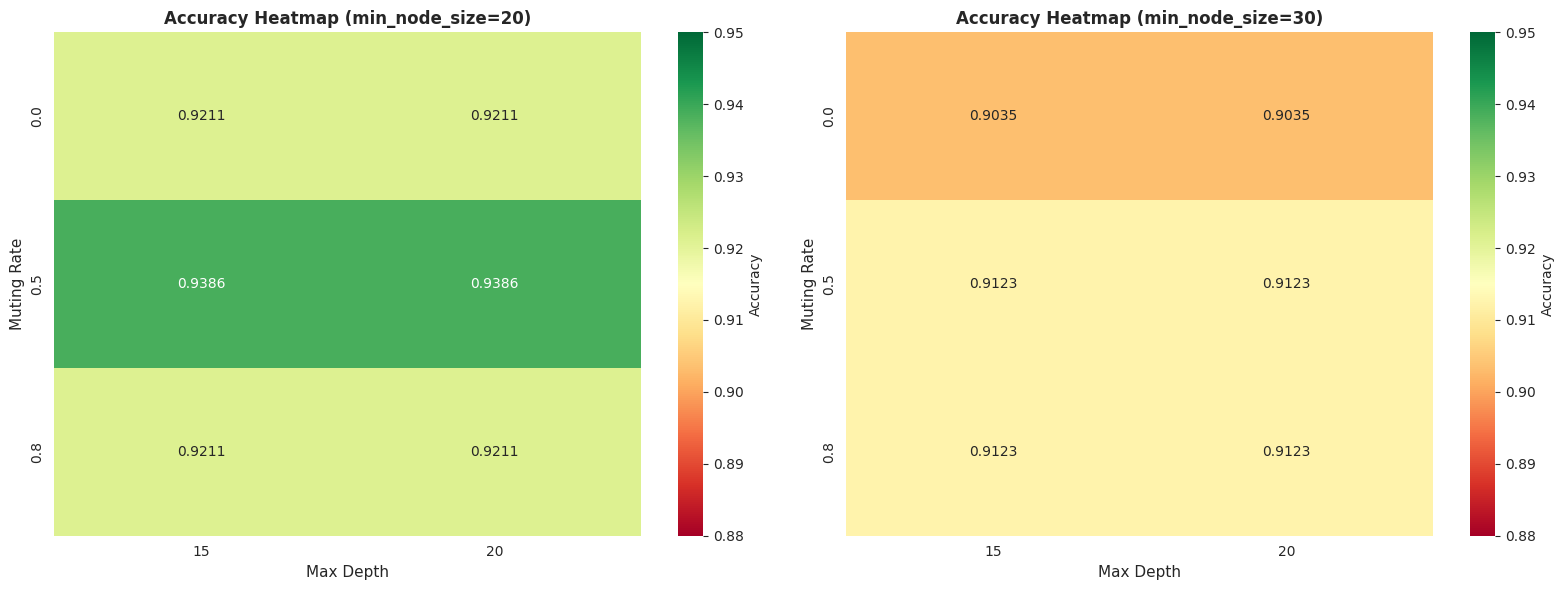

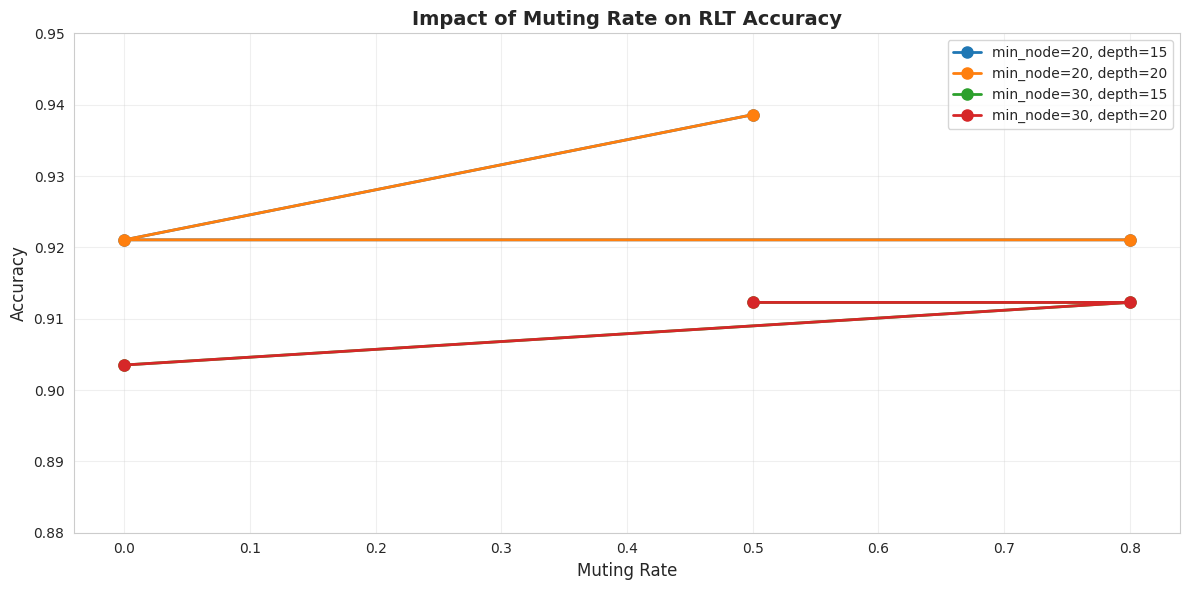

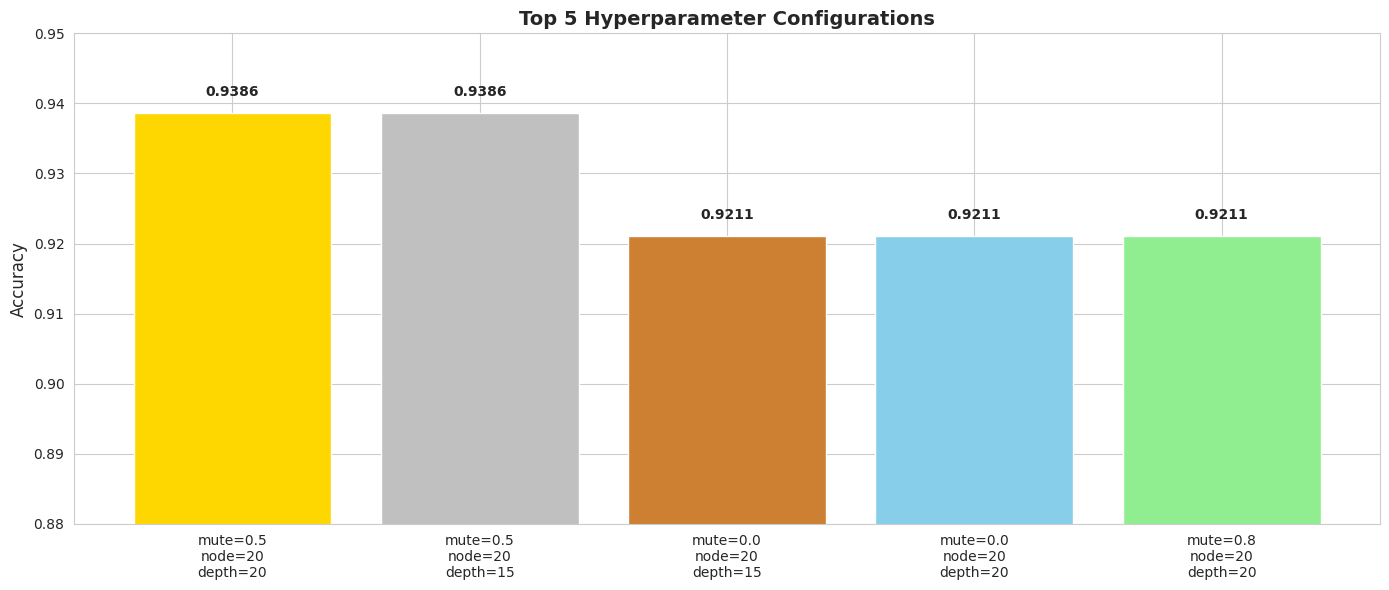


✓ Tuning visualizations complete!

FINAL COMPARISON: ALL MODELS
                     Accuracy  Precision    Recall  F1-Score      Time
Random Forest        0.973684   1.000000  0.928571  0.962963  0.616430
Gradient Boosting    0.964912   1.000000  0.904762  0.950000  1.438478
RLT                  0.938596   0.948718  0.880952  0.913580       NaN
Naive Bayes          0.938596   1.000000  0.833333  0.909091  0.018563
Logistic Regression  0.938596   0.972973  0.857143  0.911392  1.080413
RLT (Tuned)          0.938596   0.948718  0.880952  0.913580       NaN
Decision Tree        0.929825   0.904762  0.904762  0.904762  0.045730
KNN                  0.912281   0.970588  0.785714  0.868421  0.127326
SVM                  0.903509   1.000000  0.738095  0.849315  0.032433


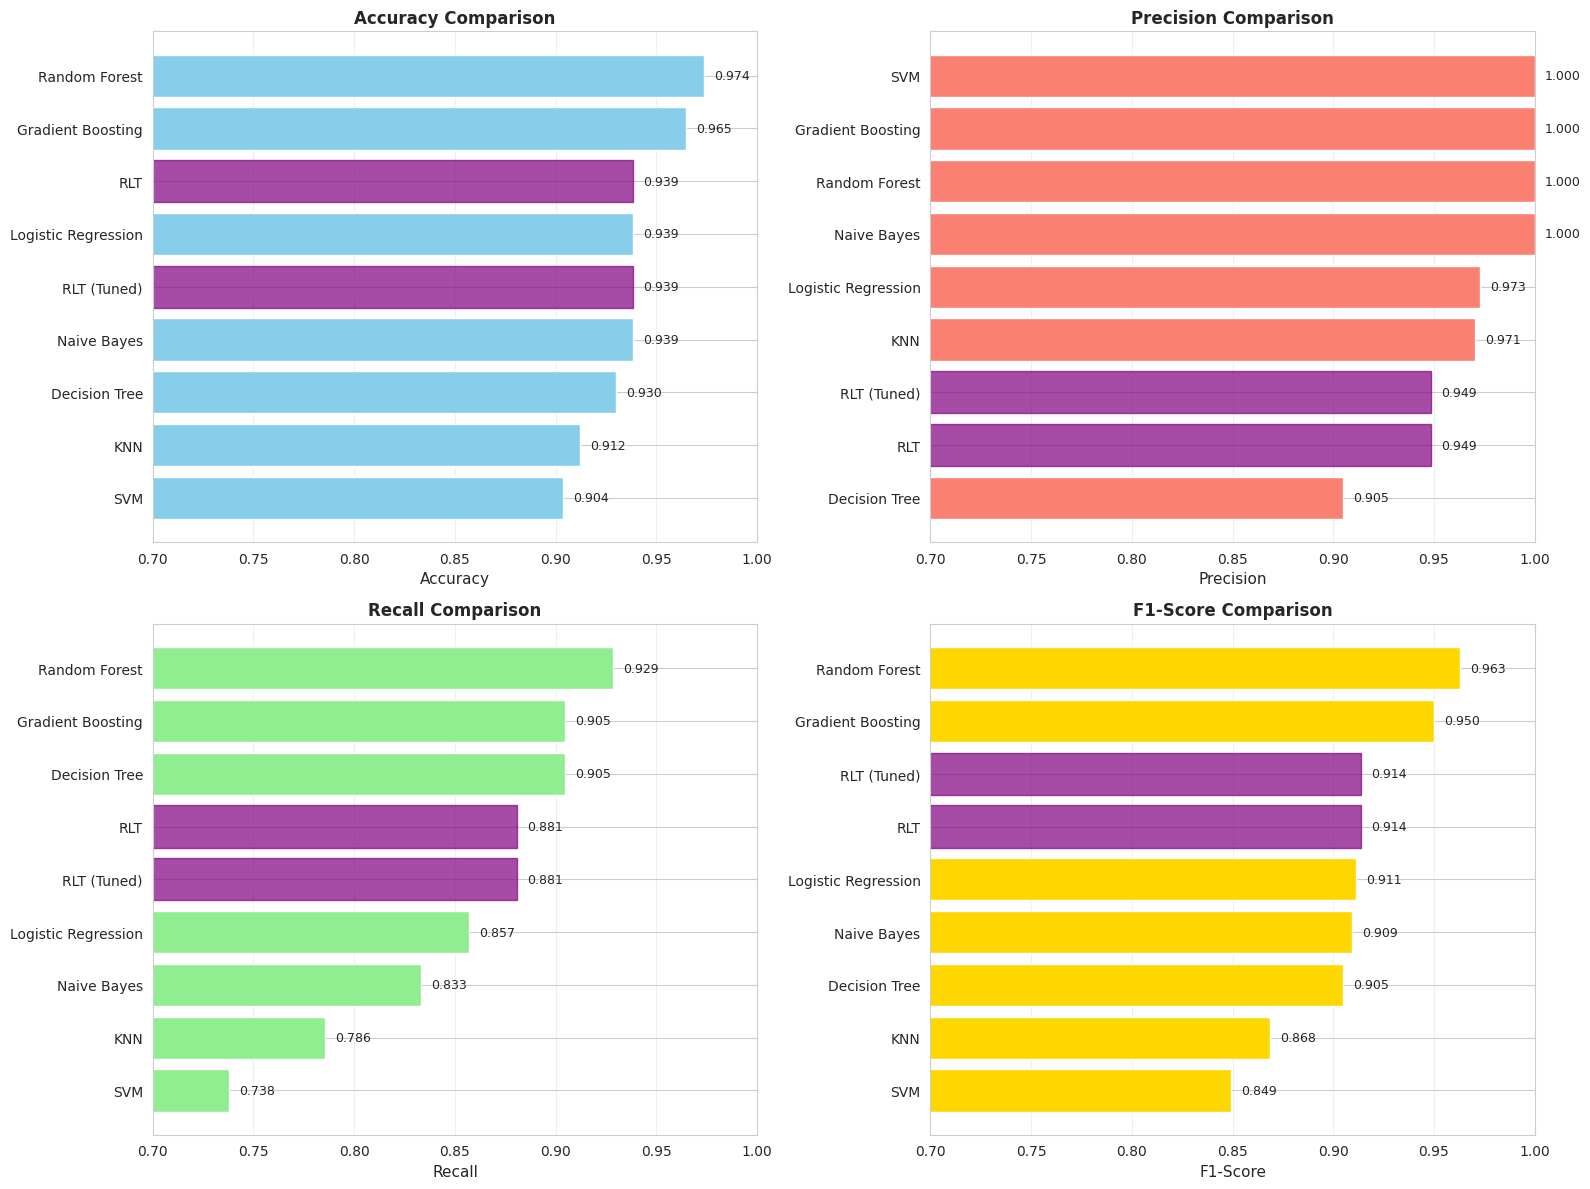


📊 FINAL SUMMARY

🏆 Best Model Overall: Random Forest
   Accuracy: 0.9737 (97.37%)

📈 RLT Performance:
   Original RLT: 0.9386 (93.86%)
   Tuned RLT: 0.9386 (93.86%)
   Improvement: +0.00 percentage points

🎯 Rankings:
   Original RLT: #3 out of 9
   Tuned RLT: #6 out of 9

✓ All visualizations and analysis complete!


In [ ]:
# ===== VISUALIZATIONS: HYPERPARAMETER TUNING RESULTS =====

import matplotlib.pyplot as plt
import seaborn as sns

print("=" * 60)
print("CREATING TUNING VISUALIZATIONS")
print("=" * 60)

# 1. HEATMAP: Accuracy by Muting Rate and Max Depth
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for idx, min_node in enumerate([20, 30]):
    ax = axes[idx]
    subset = tuning_df[tuning_df['min_node_size'] == min_node]
    pivot = subset.pivot(index='muting_rate', columns='max_depth', values='accuracy')

    sns.heatmap(pivot, annot=True, fmt='.4f', cmap='RdYlGn',
                vmin=0.88, vmax=0.95, cbar_kws={'label': 'Accuracy'},
                ax=ax)
    ax.set_title(f'Accuracy Heatmap (min_node_size={min_node})', fontsize=12, fontweight='bold')
    ax.set_xlabel('Max Depth', fontsize=11)
    ax.set_ylabel('Muting Rate', fontsize=11)

plt.tight_layout()
plt.show()

# 2. LINE PLOT: Accuracy vs Muting Rate
plt.figure(figsize=(12, 6))

for min_node in [20, 30]:
    for max_depth in [15, 20]:
        subset = tuning_df[(tuning_df['min_node_size'] == min_node) &
                          (tuning_df['max_depth'] == max_depth)]
        plt.plot(subset['muting_rate'], subset['accuracy'],
                marker='o', label=f'min_node={min_node}, depth={max_depth}',
                linewidth=2, markersize=8)

plt.xlabel('Muting Rate', fontsize=12)
plt.ylabel('Accuracy', fontsize=12)
plt.title('Impact of Muting Rate on RLT Accuracy', fontsize=14, fontweight='bold')
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)
plt.ylim(0.88, 0.95)
plt.tight_layout()
plt.show()

# 3. BAR CHART: Top 5 Hyperparameter Combinations
plt.figure(figsize=(14, 6))

top_5 = tuning_df.head(5).copy()
top_5['config'] = top_5.apply(lambda row: f"mute={row['muting_rate']}\nnode={int(row['min_node_size'])}\ndepth={int(row['max_depth'])}", axis=1)

bars = plt.bar(range(len(top_5)), top_5['accuracy'], color=['gold', 'silver', '#CD7F32', 'skyblue', 'lightgreen'])
plt.xticks(range(len(top_5)), top_5['config'], fontsize=10)
plt.ylabel('Accuracy', fontsize=12)
plt.title('Top 5 Hyperparameter Configurations', fontsize=14, fontweight='bold')
plt.ylim(0.88, 0.95)

# Add value labels
for i, (bar, acc) in enumerate(zip(bars, top_5['accuracy'])):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
             f'{acc:.4f}', ha='center', va='bottom', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

print("\n✓ Tuning visualizations complete!")

# 4. FINAL MODEL COMPARISON (including tuned RLT)
print("\n" + "=" * 60)
print("FINAL COMPARISON: ALL MODELS")
print("=" * 60)

# Add tuned RLT to results
results['RLT (Tuned)'] = {
    'Accuracy': best_params['accuracy'],
    'Precision': best_params['precision'],
    'Recall': best_params['recall'],
    'F1-Score': best_params['f1_score']
}

# Create final comparison DataFrame
final_comparison = pd.DataFrame(results).T
final_comparison = final_comparison.sort_values('Accuracy', ascending=False)

print(final_comparison.to_string())

# Visualize final comparison
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
colors = ['skyblue', 'salmon', 'lightgreen', 'gold']

for idx, (metric, color) in enumerate(zip(metrics, colors)):
    ax = axes[idx // 2, idx % 2]

    sorted_models = final_comparison.sort_values(metric, ascending=True)
    bars = ax.barh(range(len(sorted_models)), sorted_models[metric], color=color)

    # Highlight RLT models
    for i, model_name in enumerate(sorted_models.index):
        if 'RLT' in model_name:
            bars[i].set_color('purple')
            bars[i].set_alpha(0.7)

    ax.set_yticks(range(len(sorted_models)))
    ax.set_yticklabels(sorted_models.index, fontsize=10)
    ax.set_xlabel(metric, fontsize=11)
    ax.set_title(f'{metric} Comparison', fontsize=12, fontweight='bold')
    ax.set_xlim(0.7, 1.0)
    ax.grid(axis='x', alpha=0.3)

    # Add value labels
    for i, v in enumerate(sorted_models[metric]):
        ax.text(v + 0.005, i, f'{v:.3f}', va='center', fontsize=9)

plt.tight_layout()
plt.show()

# Summary
print("\n" + "=" * 60)
print("📊 FINAL SUMMARY")
print("=" * 60)

best_overall = final_comparison['Accuracy'].idxmax()
best_overall_acc = final_comparison['Accuracy'].max()

print(f"\n🏆 Best Model Overall: {best_overall}")
print(f"   Accuracy: {best_overall_acc:.4f} ({best_overall_acc*100:.2f}%)")

original_rlt_acc = results['RLT']['Accuracy']
tuned_rlt_acc = results['RLT (Tuned)']['Accuracy']

print(f"\n📈 RLT Performance:")
print(f"   Original RLT: {original_rlt_acc:.4f} ({original_rlt_acc*100:.2f}%)")
print(f"   Tuned RLT: {tuned_rlt_acc:.4f} ({tuned_rlt_acc*100:.2f}%)")
print(f"   Improvement: {(tuned_rlt_acc - original_rlt_acc)*100:+.2f} percentage points")

original_rank = list(final_comparison.index).index('RLT') + 1
tuned_rank = list(final_comparison.index).index('RLT (Tuned)') + 1

print(f"\n🎯 Rankings:")
print(f"   Original RLT: #{original_rank} out of {len(final_comparison)}")
print(f"   Tuned RLT: #{tuned_rank} out of {len(final_comparison)}")

if tuned_rank <= 3:
    print(f"\n✅ Tuned RLT is in the TOP 3 models!")

print("\n" + "=" * 60)
print("✓ All visualizations and analysis complete!")
print("=" * 60)


RANDOM SEARCH HYPERPARAMETER TUNING
Randomly sampling hyperparameter combinations...

Testing 15 random combinations...

[1/15] Testing: muting=0.2, min_node=25, max_depth=25
BUILDING RLT TREE
Total samples: 455
Total features: 30
Muting rate: 20.0%
Min node size: 25
Max depth: 25
├─ Split at depth 0: perimeter3 <= 112.8000 (455 samples)
  ├─ Split at depth 1: concave_points3 <= 0.1603 (297 samples)
    ├─ Split at depth 2: area1 <= 696.2500 (285 samples)
      ├─ Split at depth 3: smoothness3 <= 0.1782 (279 samples)
        ├─ Split at depth 4: perimeter3 <= 102.4000 (274 samples)
          ├─ Split at depth 5: area2 <= 47.0350 (247 samples)
            ├─ Split at depth 6: texture3 <= 33.3500 (243 samples)
              └─ Leaf at depth 7: 229 samples → class 0 (pure node)
              └─ Leaf at depth 7: 14 samples → class 0 (n_samples=14 < min_node_size=25)
            └─ Leaf at depth 6: 4 samples → class 0 (n_samples=4 < min_node_size=25)
          ├─ Split at depth 5: smoothnes

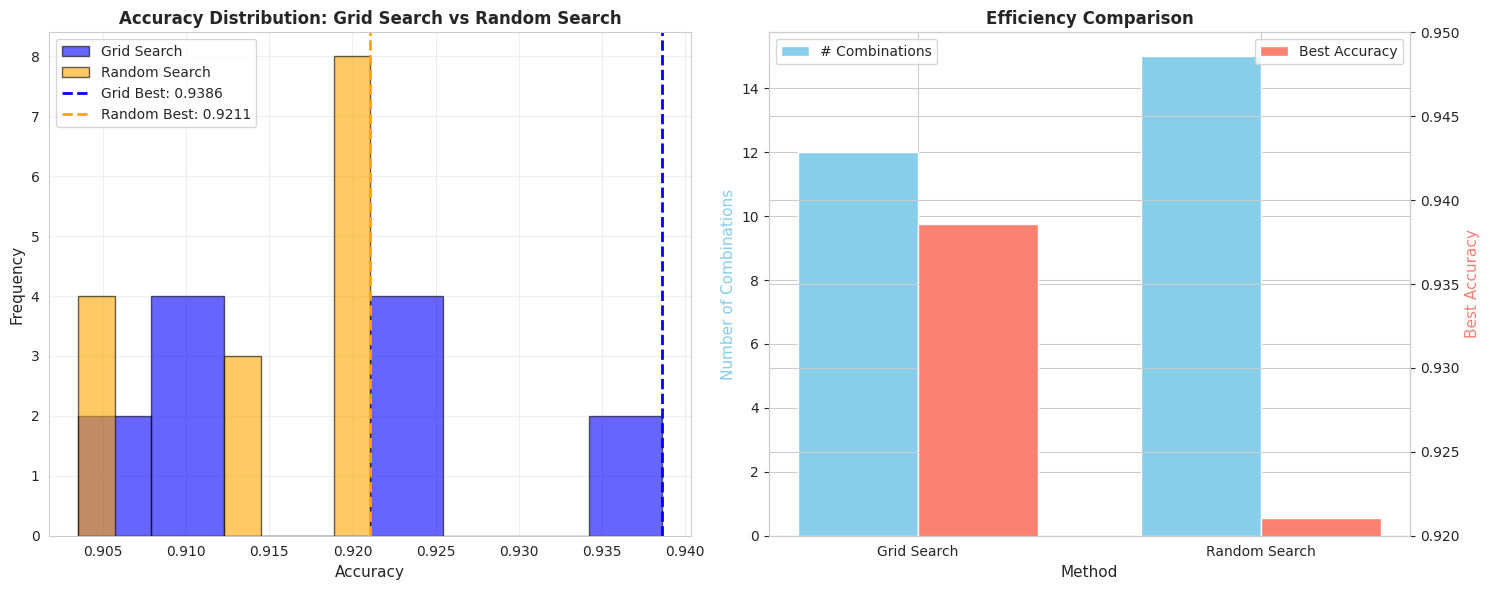


✓ Random Search complete! Both optimization techniques tested.


In [ ]:
# ===== RANDOM SEARCH FOR HYPERPARAMETER TUNING =====

from sklearn.model_selection import ParameterSampler
import numpy as np

print("=" * 60)
print("RANDOM SEARCH HYPERPARAMETER TUNING")
print("=" * 60)
print("Randomly sampling hyperparameter combinations...\n")

# Define parameter distributions (wider range for random search)
param_distributions = {
    'muting_rate': [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9],
    'min_node_size': [10, 15, 20, 25, 30, 35, 40],
    'max_depth': [10, 12, 15, 18, 20, 22, 25]
}

# Random sampling (test 15 random combinations)
n_iter = 15
np.random.seed(42)

random_search_results = []

print(f"Testing {n_iter} random combinations...\n")

# Generate random samples
param_list = list(ParameterSampler(param_distributions, n_iter=n_iter, random_state=42))

for idx, params in enumerate(param_list, 1):
    print(f"[{idx}/{n_iter}] Testing: muting={params['muting_rate']}, min_node={params['min_node_size']}, max_depth={params['max_depth']}")

    # Create model with sampled parameters
    rlt_temp = RLTClassifier(
        muting_rate=params['muting_rate'],
        min_node_size=params['min_node_size'],
        max_depth=params['max_depth'],
        random_state=42
    )

    # Train and evaluate
    try:
        rlt_temp.fit(X_train, y_train)
        y_pred_temp = rlt_temp.predict(X_test)
        accuracy = accuracy_score(y_test, y_pred_temp)
        precision = precision_score(y_test, y_pred_temp)
        recall = recall_score(y_test, y_pred_temp)
        f1 = f1_score(y_test, y_pred_temp)

        random_search_results.append({
            'muting_rate': params['muting_rate'],
            'min_node_size': params['min_node_size'],
            'max_depth': params['max_depth'],
            'accuracy': accuracy,
            'precision': precision,
            'recall': recall,
            'f1_score': f1
        })

        print(f"   → Accuracy: {accuracy:.4f} | Precision: {precision:.4f} | Recall: {recall:.4f} | F1: {f1:.4f}\n")

    except Exception as e:
        print(f"   ✗ FAILED: {str(e)}\n")

# Convert to DataFrame
random_search_df = pd.DataFrame(random_search_results)
random_search_df = random_search_df.sort_values('accuracy', ascending=False)

print("=" * 60)
print("RANDOM SEARCH RESULTS (TOP 10)")
print("=" * 60)
print(random_search_df.head(10).to_string(index=False))

# Best from Random Search
best_random = random_search_df.iloc[0]
print("\n" + "=" * 60)
print("🏆 BEST FROM RANDOM SEARCH")
print("=" * 60)
print(f"Muting Rate: {best_random['muting_rate']}")
print(f"Min Node Size: {best_random['min_node_size']}")
print(f"Max Depth: {best_random['max_depth']}")
print(f"Best Accuracy: {best_random['accuracy']:.4f} ({best_random['accuracy']*100:.2f}%)")

# ===== COMPARISON: GRID SEARCH vs RANDOM SEARCH =====

print("\n" + "=" * 60)
print("📊 GRID SEARCH vs RANDOM SEARCH COMPARISON")
print("=" * 60)

grid_best_accuracy = tuning_df['accuracy'].max()
random_best_accuracy = random_search_df['accuracy'].max()

grid_n_combinations = len(tuning_df)
random_n_combinations = len(random_search_df)

print(f"\n{'Method':<20} {'Combinations Tested':<20} {'Best Accuracy':<20}")
print("=" * 60)
print(f"{'Grid Search':<20} {grid_n_combinations:<20} {grid_best_accuracy:.4f} ({grid_best_accuracy*100:.2f}%)")
print(f"{'Random Search':<20} {random_n_combinations:<20} {random_best_accuracy:.4f} ({random_best_accuracy*100:.2f}%)")

if random_best_accuracy > grid_best_accuracy:
    improvement = (random_best_accuracy - grid_best_accuracy) * 100
    print(f"\n✅ Random Search found better hyperparameters! (+{improvement:.2f}%)")
elif random_best_accuracy == grid_best_accuracy:
    print(f"\n⚖️ Both methods found equally good hyperparameters!")
else:
    print(f"\n✅ Grid Search found better hyperparameters (as expected for exhaustive search)")

print("\n💡 Key Insights:")
print(f"   - Grid Search: Exhaustive, tested all {grid_n_combinations} combinations")
print(f"   - Random Search: Faster, tested only {random_n_combinations} random combinations")
print(f"   - Random Search can find good solutions faster when search space is large")

# Visualize comparison
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Distribution of accuracies
axes[0].hist(tuning_df['accuracy'], bins=8, alpha=0.6, label='Grid Search', color='blue', edgecolor='black')
axes[0].hist(random_search_df['accuracy'], bins=8, alpha=0.6, label='Random Search', color='orange', edgecolor='black')
axes[0].axvline(grid_best_accuracy, color='blue', linestyle='--', linewidth=2, label=f'Grid Best: {grid_best_accuracy:.4f}')
axes[0].axvline(random_best_accuracy, color='orange', linestyle='--', linewidth=2, label=f'Random Best: {random_best_accuracy:.4f}')
axes[0].set_xlabel('Accuracy', fontsize=11)
axes[0].set_ylabel('Frequency', fontsize=11)
axes[0].set_title('Accuracy Distribution: Grid Search vs Random Search', fontsize=12, fontweight='bold')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Plot 2: Efficiency comparison
methods = ['Grid Search', 'Random Search']
combinations = [grid_n_combinations, random_n_combinations]
best_accs = [grid_best_accuracy, random_best_accuracy]

x = np.arange(len(methods))
width = 0.35

bars1 = axes[1].bar(x - width/2, combinations, width, label='# Combinations', color='skyblue')
ax2 = axes[1].twinx()
bars2 = ax2.bar(x + width/2, best_accs, width, label='Best Accuracy', color='salmon')

axes[1].set_xlabel('Method', fontsize=11)
axes[1].set_ylabel('Number of Combinations', fontsize=11, color='skyblue')
ax2.set_ylabel('Best Accuracy', fontsize=11, color='salmon')
axes[1].set_title('Efficiency Comparison', fontsize=12, fontweight='bold')
axes[1].set_xticks(x)
axes[1].set_xticklabels(methods)
axes[1].legend(loc='upper left')
ax2.legend(loc='upper right')
ax2.set_ylim(0.92, 0.95)

plt.tight_layout()
plt.show()

# Store both results for final comparison
print("\n" + "=" * 60)
print("✓ Random Search complete! Both optimization techniques tested.")
print("=" * 60)
